# Perfiles de clientes BAJA+2 con LGBM — 

Adaptado del script original a notebook, con tus rutas y tu semilla real. Genera `clusters_tendencias.pdf`: perfiles de clientes BAJA+2 según qué variables usó un Random Forest para distinguirlos de clientes fieles, con la evolución mes a mes de cada variable por cluster.

**Requisitos**: `pip install duckdb pandas numpy scikit-learn matplotlib`

In [1]:
from pathlib import Path

CSV_PATH = Path("../data/competencia_01.csv.gz")
OUT_PATH = Path("./clusters_tendencias.pdf")

N_TREES = 300
MIN_SAMPLES_LEAF = 50
K = 5
TOP_N = 3
SEED = 500009          # tu semilla real
BANDA = "ic95"          # "ic95" | "desvio" | "iqr"

In [2]:
from pathlib import Path
import pandas as pd
import lightgbm as lgb
import shap
from sklearn.datasets import make_classification
from __future__ import annotations

import time

import duckdb
import matplotlib
import numpy as np
import pandas as pd

matplotlib.use("Agg")
import matplotlib.pyplot as plt
from matplotlib.backends.backend_pdf import PdfPages
from sklearn.cluster import KMeans
from sklearn.ensemble import RandomForestClassifier


ID_COL = "numero_de_cliente"
MES_COL = "foto_mes"
TARGET_COL = "clase_ternaria"
GRUPO_COL = "grupo"  # 1 = cliente BAJA+2, 0 = cliente fiel
CLUSTER_COL = "cluster"
NON_FEATURE_COLS = (ID_COL, MES_COL, TARGET_COL, GRUPO_COL)
RAIZ_COL = "_sin_split"  # hojas sin split (arbol de un solo nodo): no entran al clustering

COLORES_CLUSTER = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4"]
INK, INK_2, GRID = "#14181a", "#4b534e", "#d7dbd3"

BANDAS = {
    "ic95": ("media", "IC 95% de la media (+/- 1,96 * desvio / raiz(n))"),
    "desvio": ("media", "+/- 1 desvio estandar"),
    "iqr": ("mediana", "Q25-Q75"),
}

if K > len(COLORES_CLUSTER):
    raise ValueError(f"K maximo {len(COLORES_CLUSTER)}")
if not CSV_PATH.exists():
    raise FileNotFoundError(f"no encuentro {CSV_PATH}")

_T0 = time.time()

def log(msg: str) -> None:
    print(f"[{time.time() - _T0:6.1f}s] {msg}", flush=True)



c:\Users\mbustos_lightech\Documents\Master\DMEyF\env\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 2. Datos: todos los BAJA+2 con su historia + igual cantidad de fieles

In [3]:
_QUERY_MUESTRA = """
WITH raw AS (
    SELECT * REPLACE (CAST({id} AS BIGINT) AS {id})
    FROM read_csv(\'{csv}\', sample_size = -1)
),
churn AS (
    SELECT DISTINCT {id} FROM raw WHERE {target} = \'BAJA+2\'
),
n_meses AS (
    SELECT COUNT(DISTINCT {mes}) AS n FROM raw
),
-- fieles: presentes todos los meses y nunca BAJA+1/BAJA+2. ORDER BY hash(...) es un
-- shuffle deterministico por seed, asi el LIMIT es un muestreo reproducible.
fieles AS (
    SELECT {id}
    FROM raw
    GROUP BY {id}
    HAVING COUNT(*) = (SELECT n FROM n_meses)
       AND SUM(CASE WHEN {target} IN (\'BAJA+1\', \'BAJA+2\') THEN 1 ELSE 0 END) = 0
    ORDER BY hash({id} + {seed})
    LIMIT (SELECT COUNT(*) FROM churn)
)
SELECT raw.*, 1 AS {grupo} FROM raw JOIN churn USING ({id})
UNION ALL
SELECT raw.*, 0 AS {grupo} FROM raw JOIN fieles USING ({id})
ORDER BY {id}, {mes}
"""


def cargar_muestra(csv_path: Path, seed: int) -> pd.DataFrame:
    query = _QUERY_MUESTRA.format(
        csv=csv_path.as_posix(), id=ID_COL, mes=MES_COL, target=TARGET_COL, grupo=GRUPO_COL, seed=seed
    )
    df = duckdb.connect().execute(query).df()
    df[TARGET_COL] = df[TARGET_COL].astype("string")
    return df


def columnas_features(df: pd.DataFrame) -> list[str]:
    return [c for c in df.columns if c not in NON_FEATURE_COLS and pd.api.types.is_numeric_dtype(df[c])]

In [4]:
log(f"leyendo {CSV_PATH.name}")
df = cargar_muestra(CSV_PATH, SEED)
meses_total = sorted(df[MES_COL].unique().tolist())
meses = meses_total[:-1]  # el ultimo mes no tiene BAJA+2 con historia
feats = columnas_features(df)
por_grupo = df.groupby(GRUPO_COL)[ID_COL].agg(ids="nunique", filas="size")
log(f"muestra: {len(df):,} filas x {len(feats)} features - "
    + " - ".join(f"grupo {g}: {r.ids:,} ids / {r.filas:,} filas" for g, r in por_grupo.iterrows()))

X = df[feats].to_numpy(dtype=np.float32)
y = df[GRUPO_COL].to_numpy()
ids = df[ID_COL].to_numpy()


[   0.1s] leyendo competencia_01.csv.gz
[  54.1s] muestra: 38,713 filas x 152 features - grupo 0: 4,067 ids / 24,402 filas - grupo 1: 4,067 ids / 14,311 filas


In [5]:
df.loc[df[GRUPO_COL] == 1, "clase_ternaria"].value_counts()

clase_ternaria
CONTINUA    6148
BAJA+2      4067
BAJA+1      4067
Name: count, dtype: Int64

In [6]:
df["grupo"].value_counts()

grupo
0    24402
1    14311
Name: count, dtype: int64

# LighGBM

In [7]:
# fit a GBT model to the data
m = lgb.LGBMClassifier()
m.fit(X, y)


[LightGBM] [Info] Number of positive: 14311, number of negative: 24402
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.015753 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 18030
[LightGBM] [Info] Number of data points in the train set: 38713, number of used features: 151
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.369669 -> initscore=-0.533637
[LightGBM] [Info] Start training from score -0.533637


,boosting_type,'gbdt'
,num_leaves,31
,max_depth,-1
,learning_rate,0.1
,n_estimators,100
,subsample_for_bin,200000
,objective,None
,class_weight,None
,min_split_gain,0.0
,min_child_weight,0.001
,min_child_samples,20


# SHAP clustering supervisado

In [8]:
X.shape

(38713, 152)

In [9]:
# compute SHAP values
explainer = shap.Explainer(m)
shap_values = explainer(X)

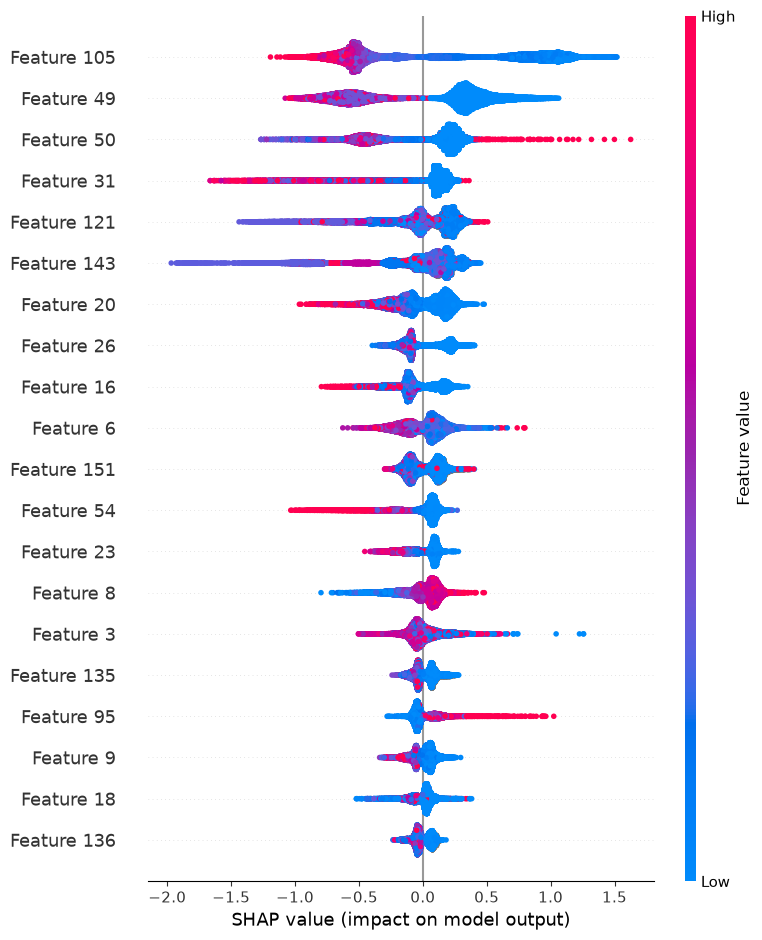

In [10]:
%matplotlib inline

# shap_values: tu matriz de valores SHAP
# X: tus datos originales
# cluster_labels: las etiquetas de clúster asignadas a cada fila
shap.summary_plot(shap_values, X, color_bar=True)

In [11]:
from umap import UMAP

# # compute 2D embedding of raw variable values
# X_2d = UMAP(
#   n_components=2, n_neighbors=200, min_dist=0
# ).fit_transform(X)

# compute 2D embedding of SHAP values
s_2d = UMAP(
  n_components=3,   # número de dimensiones de salida (querés proyectar a 2D)
  n_neighbors=100,  # cuántos vecinos se consideran para construir la estructura local
  min_dist=0        # controla qué tan apretados quedan los puntos en el espacio reducido
).fit_transform(shap_values.values[:, :])

In [12]:
s_2d.shape

(38713, 3)

C:\Users\mbustos_lightech\AppData\Local\Temp\ipykernel_27908\589397441.py:5: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  ax.scatter(s_2d[mask, 0], s_2d[mask, 1], label=group, cmap='viridis', alpha=0.7)


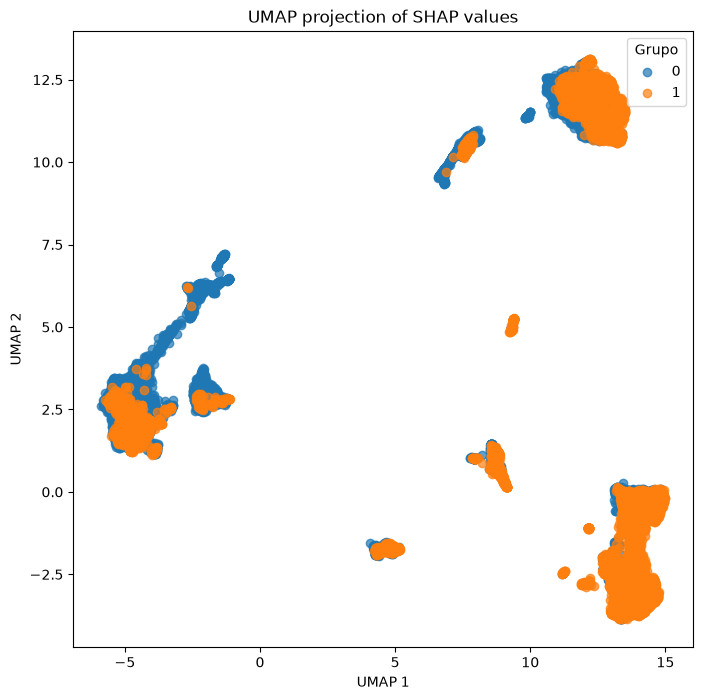

In [13]:
%matplotlib inline
fig, ax = plt.subplots(figsize=(8, 8))
for group in sorted(set(y)):
    mask = y == group
    ax.scatter(s_2d[mask, 0], s_2d[mask, 1], label=group, cmap='viridis', alpha=0.7)
ax.set_title("UMAP projection of SHAP values")
ax.set_xlabel("UMAP 1")
ax.set_ylabel("UMAP 2")
ax.legend(title="Grupo")
plt.show()

Medir qué tan bien las coordenadas de UMAP separan los grupos. Una forma sencilla es entrenar un clasificador muy básico (por ejemplo, una regresión logística) sobre las coordenadas 2D y evaluar su desempeño.

In [14]:
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score

# s_2d: coordenadas UMAP (n_samples x 2)
# y: vector con los grupos target (0/1)

# Dividir en train/test
X_train, X_test, y_train, y_test = train_test_split(s_2d, y, test_size=0.3, random_state=42)

# Entrenar clasificador simple
clf = LogisticRegression()
clf.fit(X_train, y_train)

# Evaluar
y_pred = clf.predict(X_test)
acc = accuracy_score(y_test, y_pred)

print("Accuracy sobre coordenadas UMAP:", acc)


Accuracy sobre coordenadas UMAP: 0.8128121232994662


Correlación entre coordenadas UMAP y features SHAP

Calculás la correlación entre cada coordenada UMAP (UMAP1, UMAP2) y los valores SHAP de cada feature.

Los features con mayor correlación son los que más influyen en la separación espacial.

---
## 3. UMAP a distintas dimensiones

Reducimos el espacio (154 dim) a n dimensiones con UMAP. Este número de dimensiones es un compromiso entre:
- **Suficientemente bajo** para que DBSCAN pueda encontrar densidad local
- **Suficientemente alto** para preservar estructura relevante

Exploraremos también n_components = 2,3,4,5,6,7 para analizar la sensibilidad.

In [15]:
# ── 3.1 UMAP a distintas dimensiones ─────────────────────────────────────────
X_pca = shap_values.values[:, :]
X_umap_dict = {}

N_COMPONENTS_LIST = [2,3,6]

for n in N_COMPONENTS_LIST:
    
    print(f'Calculando UMAP {n}D...')
    reducer = UMAP(
        n_components=n,
        n_neighbors=30,
        min_dist=0.1,
        random_state=SEED
    )
    X_umap_dict[n] = reducer.fit_transform(X_pca)
    print(f'  ✓ UMAP {n}D completado. Shape: {X_umap_dict[n].shape}')



Calculando UMAP 2D...


c:\Users\mbustos_lightech\Documents\Master\DMEyF\env\Lib\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


  ✓ UMAP 2D completado. Shape: (38713, 2)
Calculando UMAP 3D...


c:\Users\mbustos_lightech\Documents\Master\DMEyF\env\Lib\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


  ✓ UMAP 3D completado. Shape: (38713, 3)
Calculando UMAP 6D...


c:\Users\mbustos_lightech\Documents\Master\DMEyF\env\Lib\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


  ✓ UMAP 6D completado. Shape: (38713, 6)


In [16]:
from sklearn.metrics import silhouette_score
# ── 3.2 Visualizar calidad de la reducción por dimensión ─────────────────────
# Comparar silhouette en el espacio UMAP-nd (clase real como proxy)
print('Silhouette por espacio de representación (clase real como referencia):')
print(f'  SHAP values:  {silhouette_score(X_pca, y, sample_size=500, random_state=SEED):.4f}')
for n in N_COMPONENTS_LIST:
    sil = silhouette_score(X_umap_dict[n], y,
                           sample_size=500, random_state=SEED)
    print(f'  UMAP {n:2d}D:  {sil:.4f}')

Silhouette por espacio de representación (clase real como referencia):
  SHAP values:  0.1733
  UMAP  2D:  0.1942
  UMAP  3D:  0.1854
  UMAP  6D:  0.1771


---
## 4. Gráfico de k-distancias en espacio UMAP-nd

Repetimos el análisis de k-distancias para estimar `eps` en cada espacio UMAP reducido. Esperamos ver un **codo más pronunciado** que en el espacio PCA original.

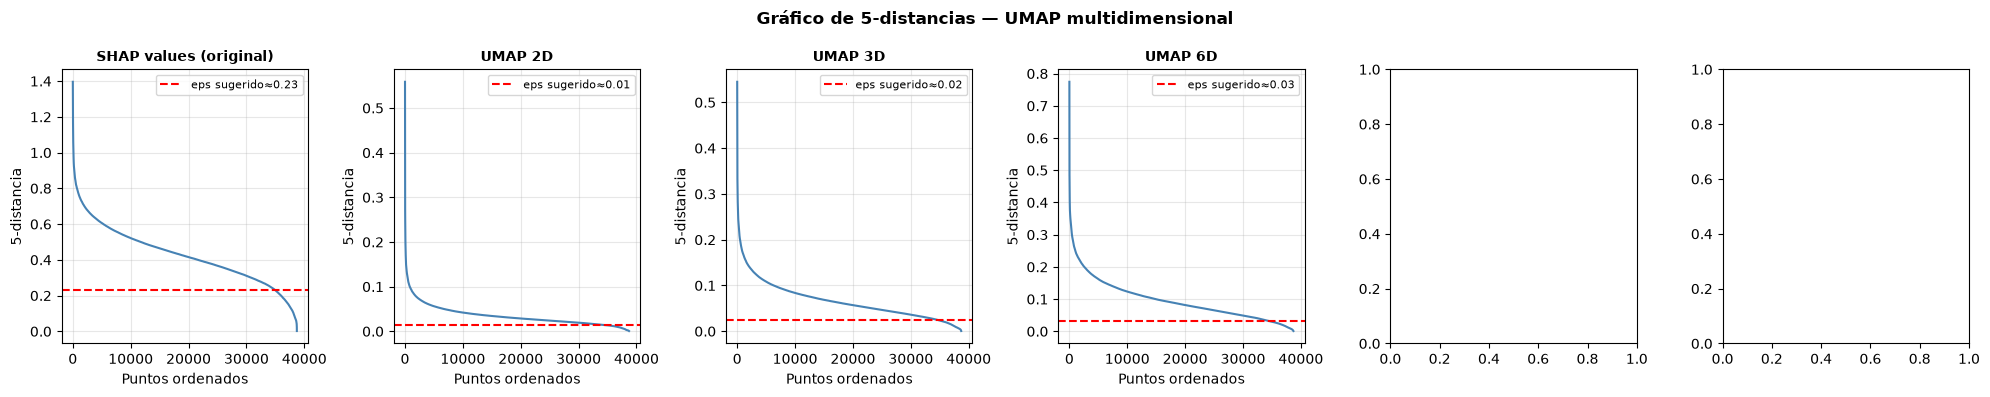


Eps sugeridos por espacio:
  SHAP values (original): eps ≈ 0.234
  UMAP 2D: eps ≈ 0.014
  UMAP 3D: eps ≈ 0.024
  UMAP 6D: eps ≈ 0.031


In [19]:
# ── 4.1 Gráfico k-distancias comparativo ─────────────────────────────────────
from sklearn.neighbors import NearestNeighbors
k_neighbors = 5
fig, axes = plt.subplots(1, 6, figsize=(20, 4))

spaces = [
    (X_pca, 'SHAP values (original)'),
    (X_umap_dict[2], 'UMAP 2D'),
    (X_umap_dict[3], 'UMAP 3D'),
    # (X_umap_dict[4], 'UMAP 4D'),
    # (X_umap_dict[5], 'UMAP 5D'),
    (X_umap_dict[6], 'UMAP 6D'),
    # (X_umap_dict[7], 'UMAP 7D'),
]

eps_suggestions = {}

for ax, (X_space, titulo) in zip(axes, spaces):
    nbrs = NearestNeighbors(n_neighbors=k_neighbors).fit(X_space)
    distances, _ = nbrs.kneighbors(X_space)
    k_dist = np.sort(distances[:, -1])[::-1]

    ax.plot(k_dist, linewidth=1.5, color='steelblue')
    ax.set_title(titulo, fontweight='bold', fontsize=10)
    ax.set_xlabel('Puntos ordenados')
    ax.set_ylabel(f'{k_neighbors}-distancia')
    ax.grid(alpha=0.3)

    # Sugerir eps como percentil 90
    eps_sug = np.percentile(k_dist, 10)  # equivale a p90 del orden descendente
    ax.axhline(eps_sug, color='red', linestyle='--',
               label=f'eps sugerido≈{eps_sug:.2f}')
    ax.legend(fontsize=8)
    eps_suggestions[titulo] = eps_sug

plt.suptitle(f'Gráfico de {k_neighbors}-distancias — UMAP multidimensional',
             fontsize=12, fontweight='bold')
plt.tight_layout()
plt.savefig('fig_umap_kdist_comparacion.png', dpi=150, bbox_inches='tight')
plt.show()

print('\nEps sugeridos por espacio:')
for titulo, eps in eps_suggestions.items():
    print(f'  {titulo}: eps ≈ {eps:.3f}')

---
## 5. DBSCAN sobre espacio UMAP

Aplicamos DBSCAN en cada espacio UMAP reducido con barrido de parámetros.

In [20]:
# ── 5.1 Barrido DBSCAN en UMAP 10D, 20D, 50D ─────────────────────────────────
from sklearn.cluster import DBSCAN

min_samples_values = [15, 20, 30, 50, 100]
results_all = {}

for n_comp in N_COMPONENTS_LIST:
    X_space = X_umap_dict[n_comp]
    # Definir rango de eps según la escala del espacio UMAP
    # nbrs = NearestNeighbors(n_neighbors=5).fit(X_space)
    # distances, _ = nbrs.kneighbors(X_space)
    # k_dist = np.sort(distances[:, -1])[::-1]
    # eps_base = np.percentile(k_dist, 10)
    # eps_values = [eps_base * f for f in [0.5, 0.75, 1.0, 1.5, 2.0, 3.0]]
    # eps_values = [round(e, 3) for e in eps_values]


    eps_values = np.arange(2, 3.1, 0.5) 
    print(f'\n=== UMAP {n_comp}D (eps range: {eps_values}) ===')
    print(f'  {"eps":>8} {"min_s":>6} {"n_clust":>8} {"n_noise":>8} {"silhouette":>11}')
    print('  ' + '-' * 50)

    best_sil = -np.inf
    best_params = None
    results_all[n_comp] = []

    

    
    for eps in eps_values:
        for min_s in min_samples_values:
            db = DBSCAN(eps=eps, min_samples=min_s, n_jobs=-1)
            labels = db.fit_predict(X_space)
            n_clusters = len(set(labels)) - (1 if -1 in labels else 0)
            n_noise = np.sum(labels == -1)

            if 2 <= n_clusters < len(X_space) - 1 and n_noise < len(X_space) * 0.9:
                sil = silhouette_score(X_space, labels,
                                       sample_size=500, random_state=SEED)
                if sil > best_sil:
                    best_sil = sil
                    best_params = (eps, min_s, labels.copy())
            else:
                sil = float('nan')

            results_all[n_comp].append((eps, min_s, n_clusters, n_noise, sil))
            print(f'  {eps:>8.3f} {min_s:>6} {n_clusters:>8} {n_noise:>8} {sil:>11.4f}')

    if best_params:
        print(f'  → Mejor: eps={best_params[0]}, min_s={best_params[1]}, Silhouette={best_sil:.4f}')
        results_all[n_comp + 1000] = best_params  # guardar con offset
    else:
        print('  → No se encontró combinación válida.')


=== UMAP 2D (eps range: [2.  2.5 3. ]) ===
       eps  min_s  n_clust  n_noise  silhouette
  --------------------------------------------------
     2.000     15        6        0      0.5808
     2.000     20        6        0      0.5808
     2.000     30        6        0      0.5808
     2.000     50        6        0      0.5808
     2.000    100        6        0      0.5808
     2.500     15        4        0      0.5979
     2.500     20        4        0      0.5979
     2.500     30        4        0      0.5979
     2.500     50        4        0      0.5979
     2.500    100        4        0      0.5979
     3.000     15        3        0      0.2648
     3.000     20        3        0      0.2648
     3.000     30        3        0      0.2648
     3.000     50        3        0      0.2648
     3.000    100        3        0      0.2648
  → Mejor: eps=2.5, min_s=15, Silhouette=0.5979

=== UMAP 3D (eps range: [2.  2.5 3. ]) ===
       eps  min_s  n_clust  n_noise  silhou

## 5.4 Matrices de confusión para los mejores resultados

In [21]:
# ── 5.2 DBSCAN final con mejores parámetros por espacio ──────────────────────
from sklearn.metrics import adjusted_rand_score, normalized_mutual_info_score as nmi_score
from sklearn.metrics.cluster import v_measure_score as van_dongen_score
dbscan_results = {}

for n_comp in N_COMPONENTS_LIST:
    if n_comp + 1000 not in results_all:
        print(f'UMAP {n_comp}D: no hay combinación válida.')
        continue

    best_eps, best_min_s, labels_best = results_all[n_comp + 1000]
    X_space = X_umap_dict[n_comp]

    n_clusters = len(set(labels_best)) - (1 if -1 in labels_best else 0)
    n_noise = np.sum(labels_best == -1)
    sil = silhouette_score(X_space, labels_best, sample_size=500, random_state=SEED)
    ari = adjusted_rand_score(y, labels_best)
    vd  = van_dongen_score(y, labels_best)
    nmi = nmi_score(y, labels_best)

    dbscan_results[n_comp] = {
        'eps': best_eps, 'min_s': best_min_s, 'labels': labels_best,
        'n_clusters': n_clusters, 'n_noise': n_noise,
        'sil': sil, 'ari': ari, 'vd': vd, 'nmi': nmi
    }

    print(f'\nDBSCAN + UMAP {n_comp}D (eps={best_eps}, min_s={best_min_s})')
    print(f'  Clusters encontrados: {n_clusters}')
    print(f'  Puntos de ruido: {n_noise} ({n_noise/len(labels_best)*100:.1f}%)')
    print(f'  Silhouette : {sil:.4f}')
    print(f'  ARI        : {ari:.4f}')
    print(f'  Van Dongen : {vd:.4f}')
    print(f'  NMI        : {nmi:.4f}')


DBSCAN + UMAP 2D (eps=2.5, min_s=15)
  Clusters encontrados: 4
  Puntos de ruido: 0 (0.0%)
  Silhouette : 0.5979
  ARI        : 0.2036
  Van Dongen : 0.1784
  NMI        : 0.1784

DBSCAN + UMAP 3D (eps=2.5, min_s=15)
  Clusters encontrados: 8
  Puntos de ruido: 0 (0.0%)
  Silhouette : 0.6498
  ARI        : 0.1759
  Van Dongen : 0.2027
  NMI        : 0.2027

DBSCAN + UMAP 6D (eps=2.0, min_s=15)
  Clusters encontrados: 10
  Puntos de ruido: 0 (0.0%)
  Silhouette : 0.6960
  ARI        : 0.1414
  Van Dongen : 0.1925
  NMI        : 0.1925


In [22]:
# ── 5.4 Matrices de confusión para los mejores resultados ────────────────────
CLASSES = [0, 1]
N_CLASSES = len(CLASSES)


for n_comp in N_COMPONENTS_LIST:
    if n_comp not in dbscan_results:
        continue
    r = dbscan_results[n_comp]
    if r['n_clusters'] == N_CLASSES:
        # Excluir puntos de ruido para la matriz de confusión
        mask_no_noise = r['labels'] != -1
        y_true_clean = y_true[mask_no_noise]
        labels_clean = r['labels'][mask_no_noise]
        
        labels_mapped = best_cluster_assignment(y_true_clean, labels_clean, N_CLASSES)
        plot_confusion_matrix(
            y_true_clean, labels_mapped, CLASSES,
            f'DBSCAN + UMAP {n_comp}D (eps={r["eps"]:.2f}, min_s={r["min_s"]})\n'
            f'({r["n_noise"]} puntos de ruido excluidos)',
            f'fig_dbscan_umap{n_comp}d_confusion.png'
        )
    else:
        print(f'UMAP {n_comp}D: {r["n_clusters"]} clusters (≠5), omitiendo matriz de confusión.')

UMAP 2D: 4 clusters (≠5), omitiendo matriz de confusión.
UMAP 3D: 8 clusters (≠5), omitiendo matriz de confusión.
UMAP 6D: 10 clusters (≠5), omitiendo matriz de confusión.


In [23]:
for n_comp in N_COMPONENTS_LIST:
    if n_comp not in dbscan_results:
        continue
    r = dbscan_results[n_comp]
    print(r)

{'eps': np.float64(2.5), 'min_s': 15, 'labels': array([0, 0, 0, ..., 2, 3, 2], shape=(38713,)), 'n_clusters': 4, 'n_noise': np.int64(0), 'sil': 0.5978944301605225, 'ari': 0.20355715073068062, 'vd': 0.17837765158105293, 'nmi': 0.17837765158105295}
{'eps': np.float64(2.5), 'min_s': 15, 'labels': array([0, 0, 0, ..., 2, 5, 2], shape=(38713,)), 'n_clusters': 8, 'n_noise': np.int64(0), 'sil': 0.6497507095336914, 'ari': 0.17593040155695558, 'vd': 0.202678130557858, 'nmi': 0.20267813055785802}
{'eps': np.float64(2.0), 'min_s': 15, 'labels': array([0, 0, 0, ..., 2, 7, 2], shape=(38713,)), 'n_clusters': 10, 'n_noise': np.int64(0), 'sil': 0.6959907412528992, 'ari': 0.1414046478913491, 'vd': 0.19251966924632458, 'nmi': 0.19251966924632458}


In [24]:
dbscan_results[2]["labels"]

array([0, 0, 0, ..., 2, 3, 2], shape=(38713,))

## clusters con el target

### UMAP 2D


In [25]:
# clusters: array con el cluster asignado a cada observación
clusters = dbscan_results[2]["labels"]  # Usando UMAP 2D como ejemplo
# y: array con el target (0 = sigue, 1 = baja)

df_cluster = pd.DataFrame({
    "Cluster": clusters,
    "Target": y
})

# 1. Proporción de bajas por cluster
tabla = pd.crosstab(df_cluster["Cluster"], df_cluster["Target"], normalize="index")
print("Proporción de bajas por cluster:\n", tabla)

# 2. Estadísticas descriptivas de features por cluster
stats = df_cluster  .groupby("Cluster").mean()
print("Medias de features por cluster:\n", stats)

# 3. Si querés ver solo los clusters con más bajas
clusters_riesgo = tabla[1].sort_values(ascending=False)
print("Clusters ordenados por proporción de bajas:\n", clusters_riesgo)


Proporción de bajas por cluster:
 Target          0         1
Cluster                    
0        0.701247  0.298753
1        0.864685  0.135315
2        0.196223  0.803777
3        0.646941  0.353059
Medias de features por cluster:
            Target
Cluster          
0        0.298753
1        0.135315
2        0.803777
3        0.353059
Clusters ordenados por proporción de bajas:
 Cluster
2    0.803777
3    0.353059
0    0.298753
1    0.135315
Name: 1, dtype: float64


b) Perfil de motivo de churn (SHAP por cluster):

In [26]:
df_shap_values = pd.DataFrame(shap_values.values, columns=feats)
# Top 3 drivers de churn por cluster
for c in df_cluster['Cluster'].unique():
    if c == -1: continue # ruido de DBSCAN
    shap_mean_cluster = df_shap_values[df_cluster['Cluster']==c].mean(axis=0)
    top_features = pd.Series(shap_mean_cluster, index=feats).sort_values(ascending=False).head(5)
    print(f"Cluster {c}: {top_features}")

Cluster 0: cpayroll_trx                  0.472769
mpayroll                      0.222621
mcomisiones_mantenimiento     0.041525
ccomisiones_mantenimiento     0.032317
chomebanking_transacciones    0.022150
dtype: float64
Cluster 1: chomebanking_transacciones    0.014819
mcomisiones_otras             0.013920
Master_fechaalta              0.013685
Visa_status                   0.007488
Master_status                 0.006611
dtype: float64
Cluster 2: ctrx_quarter             0.939972
cpayroll_trx             0.334428
mpayroll                 0.225765
mprestamos_personales    0.169678
Visa_fultimo_cierre      0.100664
dtype: float64
Cluster 3: ctrx_quarter             0.938333
mprestamos_personales    0.130069
Visa_fultimo_cierre      0.077441
Visa_mpagominimo         0.057322
mautoservicio            0.056211
dtype: float64


### UMAP 6D

In [31]:
df.shape

(38713, 158)

In [32]:
# clusters: array con el cluster asignado a cada observación
clusters = dbscan_results[6]["labels"]  # Usando UMAP 2D como ejemplo
# y: array con el target (0 = sigue, 1 = baja)
# X: DataFrame con las features originales

# df_cluster = pd.DataFrame(X, columns=feats)  # tus features originales
df["Cluster"] = clusters
df["Target"] = y

# 1. Proporción de bajas por cluster
tabla = pd.crosstab(df["Cluster"], df["Target"], normalize="index")
print("Proporción de bajas por cluster:\n", tabla)

# 2. Estadísticas descriptivas de features por cluster
stats = df.groupby("Cluster").agg("mean", numeric_only=True)
print("Medias de features por cluster:\n", stats)

# 3. Si querés ver solo los clusters con más bajas
clusters_riesgo = tabla[1].sort_values(ascending=False)
print("Clusters ordenados por proporción de bajas:\n", clusters_riesgo)


Proporción de bajas por cluster:
 Target          0         1
Cluster                    
0        0.699225  0.300775
1        0.927744  0.072256
2        0.198685  0.801315
3        0.038217  0.961783
4        0.967742  0.032258
5        0.998837  0.001163
6        0.321452  0.678548
7        0.674677  0.325323
8        0.021277  0.978723
9        1.000000  0.000000
Medias de features por cluster:
          numero_de_cliente       foto_mes  active_quarter  cliente_vip  \
Cluster                                                                  
0             3.512108e+07  202105.236727        0.997050     0.002275   
1             3.832517e+07  202105.080757        1.000000     0.002975   
2             4.127893e+07  202104.598115        0.814960     0.001374   
3             3.907959e+07  202104.939490        0.907643     0.000000   
4             4.010979e+07  202105.092166        1.000000     0.000000   
5             3.908939e+07  202107.790576        1.000000     0.003490   
6    

In [33]:
# Filtrar clusters con más del 50% de bajas  
clusters_riesgo = tabla.loc[tabla[1] > 0.5].index 
clusters_riesgo

Index([2, 3, 6, 8], dtype='int64', name='Cluster')

 ### Visualizaciones
 Para visualizar los perfiles de tus clusters junto con el target, un heatmap es muy útil porque muestra de manera compacta las medias de las features por cluster y te permite detectar rápidamente qué atributos diferencian a los grupos con más bajas.

TypeError: Image data of dtype object cannot be converted to float

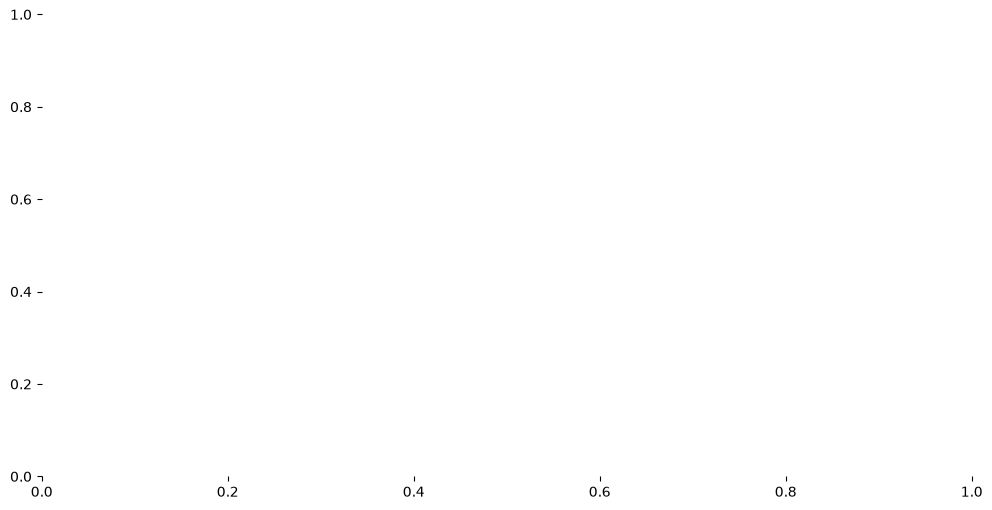

In [30]:
import seaborn as sns

# Calcular medias de features por cluster
stats = df.loc[df["Cluster"].isin(clusters_riesgo)].groupby("Cluster").agg("mean", numeric_only=True)

# Heatmap de medias
plt.figure(figsize=(12,6))
sns.heatmap(stats.T, cmap="coolwarm", fmt=".2f")
plt.title("Medias de features por cluster")
plt.ylabel("Features")
plt.xlabel("Cluster")
plt.show()

a) Perfil descriptivo

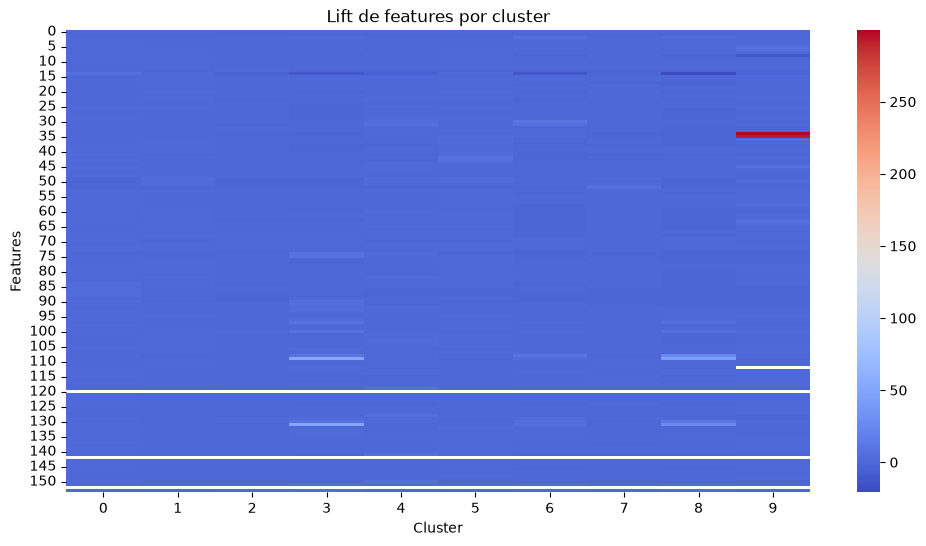

In [ ]:
# Asumiendo df con features + 'cluster' + 'shap_values' + 'churn_prob'
profile = df.groupby('Cluster').mean().round(2)

# % vs global para ver qué lo hace distinto
global_mean = df.mean(numeric_only=True)
lift = profile / global_mean - 1  # >20% = sobre-indexado

# Heatmap de medias
plt.figure(figsize=(12,6))
sns.heatmap(lift.T, cmap="coolwarm", fmt=".2f")
plt.title("Lift de features por cluster")
plt.ylabel("Features")
plt.xlabel("Cluster")
plt.show()

In [ ]:
lift

,0,1,2,3,4,5,6,7,8,9,...,144,145,146,147,148,149,150,151,Cluster,Target
Cluster,,,,,,,,,,,,,,,,,,,,,
0,0.057212,-1.000000,-0.710377,0.040445,0.154459,0.184303,0.170419,0.462494,0.920870,0.300958,...,0.268213,0.206491,0.432365,0.161527,0.244762,0.235454,-1.000000,0.134727,NaN,0.000895
1,0.036068,4.161733,-0.613835,0.085177,0.195040,0.838643,0.603217,0.841753,0.741754,0.785616,...,1.050035,0.397870,1.767594,0.204291,0.362003,0.168823,0.857452,0.493930,NaN,-1.000000
2,0.057212,-1.000000,-0.806918,-0.060625,0.060654,-0.238592,-0.162228,-0.317542,1.109392,0.535043,...,0.294596,0.097344,-0.099568,0.026011,0.122362,0.135508,-1.000000,-0.273364,NaN,-0.810641
3,-0.143658,-1.000000,0.544658,0.037069,-0.165119,-0.136079,-0.255562,-0.115290,-1.267824,-0.742194,...,-0.769273,-0.681079,-0.788769,-0.152186,-0.710996,-0.694607,-1.000000,-0.568793,NaN,1.164098
4,-0.037937,-1.000000,1.799693,0.063655,0.005323,0.169071,0.138994,-0.144953,-1.992423,-0.651939,...,-0.735196,-0.367185,-0.942952,0.021014,-0.771870,-0.672396,-1.000000,3.667818,NaN,1.596917
5,0.057212,-1.000000,0.255035,-0.101137,-0.002794,-0.353863,-0.114868,-0.376067,-0.276174,-0.292429,...,-0.060835,0.079691,-0.793394,-0.094449,0.014702,0.128567,4.572356,0.576587,NaN,-0.918846
6,0.057212,-1.000000,-0.710377,-0.064634,0.031544,-0.002804,-0.116706,-0.102050,0.951492,0.586181,...,0.360707,0.285184,1.164736,-0.031219,0.307329,0.238231,-1.000000,0.086311,NaN,-1.000000
7,0.004352,-1.000000,5.950963,-0.035094,-0.286628,0.166534,0.594159,-0.246463,-2.461033,-0.801766,...,-0.913955,-0.796856,-1.000000,-0.392015,-0.848191,-0.850080,-1.000000,2.471150,NaN,0.839483
8,0.057212,-1.000000,0.641199,0.033482,0.056751,0.666292,0.673615,0.710517,-0.897731,-0.186051,...,0.414033,0.297557,-0.677756,0.053380,0.293224,0.304862,2.714904,1.549262,NaN,-0.540129


b) Perfil de motivo de churn (SHAP por cluster):

In [34]:
df_shap_values = pd.DataFrame(shap_values.values, columns=feats)
# Top 3 drivers de churn por cluster
for c in df['Cluster'].unique():
    if c == -1: continue # ruido de DBSCAN
    shap_mean_cluster = df_shap_values[df['Cluster']==c].mean(axis=0)
    top_features = pd.Series(shap_mean_cluster, index=feats).sort_values(ascending=False).head(5)
    print(f"Cluster {c}: {top_features}")

Cluster 0: cpayroll_trx                  0.479197
mpayroll                      0.227232
mcomisiones_mantenimiento     0.041829
ccomisiones_mantenimiento     0.032523
chomebanking_transacciones    0.022530
dtype: float64
Cluster 1: mprestamos_personales         0.103259
Visa_fultimo_cierre           0.043784
chomebanking_transacciones    0.023859
mcomisiones_otras             0.015499
Master_fechaalta              0.010117
dtype: float64
Cluster 2: ctrx_quarter             0.938158
cpayroll_trx             0.334644
mpayroll                 0.226293
mprestamos_personales    0.169573
Visa_fultimo_cierre      0.100338
dtype: float64
Cluster 3: Master_status            0.789589
Visa_status              0.716386
ctrx_quarter             0.659067
cpayroll_trx             0.399247
mtarjeta_visa_consumo    0.252577
dtype: float64
Cluster 4: Visa_fultimo_cierre      0.064826
Master_fechaalta         0.018050
Master_fultimo_cierre    0.017156
mcomisiones_otras        0.013637
ccaja_seguridad    

Es simplemente el promedio de la probabilidad que te devuelve tu LGBM, pero dentro de cada cluster.
Tu LGBM no predice 0 o 1, predice predict_proba -> un número entre 0 y 1.

In [35]:

# 1. Si todavía no tenés la proba en el df
import lightgbm as lgb

# X son tus features
df['churn_prob'] = m.predict_proba(X)[:, 1]  # [:, 1] es la proba de clase 1 = churn

# 2. La media por cluster
churn_prob_media = df.groupby('Cluster')['churn_prob'].mean()

print(churn_prob_media)

# Ejemplo de salida:
# cluster
#  0    0.78  -> En promedio, 78% de probabilidad de irse
#  1    0.31
#  2    0.65
# -1    0.45  -> Ruido de DBSCAN

Cluster
0    0.299693
1    0.071370
2    0.798271
3    0.948382
4    0.043828
5    0.011744
6    0.681138
7    0.336804
8    0.947080
9    0.012226
Name: churn_prob, dtype: float64


Me quedo con los cluster que tengan prob_churn > 60%  

In [ ]:
cluster_churn_stats = df.groupby('Cluster')['churn_prob'].agg(['mean'])
cluster_churn_stats = cluster_churn_stats.loc[cluster_churn_stats['mean'] > 0.6 ].index  
cluster_churn_stats

Index([2, 3, 6, 8], dtype='int64', name='Cluster')

In [ ]:
# Top 5 drivers de churn por cluster
for c in cluster_churn_stats:
    if c == -1: continue # ruido de DBSCAN
    shap_mean_cluster = df_shap_values[df['Cluster']==c].mean(axis=0)
    top_features = pd.Series(shap_mean_cluster, index=feats).sort_values(ascending=False).head(5)
    print(f"Cluster {c}: {top_features}")

Cluster 2: ctrx_quarter             0.938158
cpayroll_trx             0.334644
mpayroll                 0.226293
mprestamos_personales    0.169573
Visa_fultimo_cierre      0.100338
dtype: float64
Cluster 3: Master_status            0.789589
Visa_status              0.716386
ctrx_quarter             0.659067
cpayroll_trx             0.399247
mtarjeta_visa_consumo    0.252577
dtype: float64
Cluster 6: ctrx_quarter             0.978554
cpayroll_trx             0.252467
mtarjeta_visa_consumo    0.168093
mcuentas_saldo           0.150645
mpayroll                 0.136949
dtype: float64
Cluster 8: ctrx_quarter             1.074909
Master_status            0.584929
cpayroll_trx             0.321096
mtarjeta_visa_consumo    0.216872
mcuentas_saldo           0.193832
dtype: float64


Pro tip: Además de la media, sacá el count y el percentil 90:

## Perfil de lift

In [ ]:
churn_global = df['churn_prob'].mean() # ej: 0.15
churn_prob_media = df.groupby('Cluster')['churn_prob'].mean()

lift = round(churn_prob_media / churn_global, 2)

print("Probabilidade de churn por cluster:\n", churn_prob_media)
print(f"Churn global: {churn_global:.2%}")
print(f"El lift de cada cluster respecto al churn global es: \n{lift}")

# Ejemplo:
# Cluster 2: 0.85 / 0.15 = 5.6x
# Cluster 1: 0.72 / 0.15 = 4.8x# feats

Probabilidade de churn por cluster:
 Cluster
0    0.299693
1    0.071370
2    0.798271
3    0.948382
4    0.043828
5    0.011744
6    0.681138
7    0.336804
8    0.947080
9    0.012226
Name: churn_prob, dtype: float64
Churn global: 36.97%
El lift de cada cluster respecto al churn global es: 
Cluster
0    0.81
1    0.19
2    2.16
3    2.57
4    0.12
5    0.03
6    1.84
7    0.91
8    2.56
9    0.03
Name: churn_prob, dtype: float64x


In [ ]:
# df.to_csv("../output/df_clusters_churn.csv", index=False)  

In [ ]:
df.groupby('Cluster')['churn_prob'].agg(['mean', 'count', lambda x: x.quantile(0.9)])

,mean,count,<lambda_0>
Cluster,,,
0,0.299693,11866,0.760417
1,0.071370,9411,0.146291
2,0.798271,10187,0.952060
3,0.948382,314,0.988826
4,0.043828,2387,0.083882
5,0.011744,1719,0.021936
6,0.681138,1515,0.938827
7,0.336804,1082,0.790618
8,0.947080,141,0.977090


Por cada cluster, sacaste el mean(|SHAP|) de las top 5 variables y te quedaste solo con clusters donde ese promedio era > 0.60. Si hiciste esto, está perfecto. Te quedaste con los clusters donde el modelo está MUY seguro de por qué se van.

In [44]:
# Esto es lo que valida tu filtro
shap_abs = np.abs(shap_values) # matriz de shap
df['shap_confidence'] = shap_abs.mean(axis=1) # que tan seguro está el modelo de por qué se va ese cliente

# Promedio por cluster
conf_por_cluster = df.groupby('cluster')['shap_confidence'].mean().sort_values(ascending=False)

# Te quedas con los de > 0.6 o con percentil 75
clusters_validos = conf_por_cluster[conf_por_cluster > conf_por_cluster.quantile(0.75)].index



KeyboardInterrupt: 

### Cluster churn bajo
Grupo de clientes que tiene baja prob de churn.

In [45]:
prob_chun_baja = lift[lift < 0.1].index

# Top 5 drivers de churn por cluster
for c in prob_chun_baja:
    if c == -1: continue # ruido de DBSCAN
    shap_mean_cluster = df_shap_values[df['Cluster']==c].mean(axis=0)
    top_features = pd.Series(shap_mean_cluster, index=feats).sort_values(ascending=False).head(5)
    print(f"Cluster {c} no explicable / Atípico: {top_features}")


Cluster 5 no explicable / Atípico: chomebanking_transacciones    0.020250
mcomisiones_otras             0.009899
mtransferencias_emitidas      0.008170
Visa_mconsumospesos           0.007462
thomebanking                  0.005224
dtype: float64
Cluster 9 no explicable / Atípico: mactivos_margen                0.094473
Master_mlimitecompra           0.026393
Master_mfinanciacion_limite    0.026124
chomebanking_transacciones     0.017402
Master_Fvencimiento            0.015878
dtype: float64


# DBSCAN

sin UMAP

In [ ]:
# Si el modelo es binario, TreeExplainer puede devolver una lista; tomamos la clase 1
if isinstance(shap_values, list):
    shap_values = shap_values[1]

In [ ]:
S = shap_values.values

shap_df = pd.DataFrame(
    S,
    columns=df[feats].columns
)

In [ ]:
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import DBSCAN
# 3. Escalar las explicaciones
S_scaled = StandardScaler().fit_transform(shap_df)

# 4. Agrupar con DBSCAN
dbscan = DBSCAN(
    eps=2,
    min_samples=20,
    metric="euclidean"
)

clusters = dbscan.fit_predict(S_scaled)

resultado = df.copy()
resultado["cluster"] = clusters
# resultado["prediccion"] = modelo.predict_proba(X_test)[:, 1]

In [ ]:
shap_por_cluster = shap_df.copy()
shap_por_cluster["cluster"] = clusters

# Influencia media firmada
media_shap = shap_por_cluster.groupby("cluster").mean()

# Importancia media absoluta
importancia_cluster = (
    shap_por_cluster
    .drop(columns="cluster")
    .abs()
    .assign(cluster=clusters)
    .groupby("cluster")
    .mean()
)

display(media_shap)
display(importancia_cluster)

,active_quarter,cliente_vip,internet,cliente_edad,cliente_antiguedad,mrentabilidad,mrentabilidad_annual,mcomisiones,mactivos_margen,mpasivos_margen,...,Visa_madelantodolares,Visa_fultimo_cierre,Visa_mpagado,Visa_mpagospesos,Visa_mpagosdolares,Visa_fechaalta,Visa_mconsumototal,Visa_cconsumos,Visa_cadelantosefectivo,Visa_mpagominimo
cluster,,,,,,,,,,,,,,,,,,,,,
-1,-0.000025,0.0,-0.000112,0.005273,-0.001229,0.000147,0.000629,0.000294,-0.005080,0.002987,...,0.0,-0.012566,0.000708,0.005560,0.000847,0.002859,0.0,0.000914,0.0,-0.002142
0,-0.000572,0.0,0.002658,0.036249,0.015551,0.013010,0.030069,-0.000567,0.086644,0.064735,...,0.0,0.125311,0.004341,0.062649,0.003696,0.053914,0.0,0.009534,0.0,0.158824
1,-0.001294,0.0,0.000563,0.098693,0.006614,0.000317,0.086717,0.005555,0.079291,0.062186,...,0.0,0.139070,0.004871,0.061590,0.003983,0.064623,0.0,0.010031,0.0,0.148262
2,-0.001434,0.0,-0.000952,0.060981,0.012072,0.022320,0.105206,-0.000305,0.087687,0.064818,...,0.0,0.127705,-0.002062,0.031517,0.003401,-0.105001,0.0,0.007033,0.0,0.119254
3,-0.001640,0.0,0.000207,-0.191682,-0.015119,0.021714,0.098273,-0.000401,0.120382,0.069972,...,0.0,0.120381,-0.002043,0.015985,0.003712,-0.125070,0.0,0.006579,0.0,0.114376
4,-0.001540,0.0,0.000626,0.007482,0.042175,0.031285,0.149782,0.000326,0.101391,0.075846,...,0.0,0.148370,-0.001890,0.031021,0.003211,0.027530,0.0,0.005873,0.0,0.143054


,active_quarter,cliente_vip,internet,cliente_edad,cliente_antiguedad,mrentabilidad,mrentabilidad_annual,mcomisiones,mactivos_margen,mpasivos_margen,...,Visa_madelantodolares,Visa_fultimo_cierre,Visa_mpagado,Visa_mpagospesos,Visa_mpagosdolares,Visa_fechaalta,Visa_mconsumototal,Visa_cconsumos,Visa_cadelantosefectivo,Visa_mpagominimo
cluster,,,,,,,,,,,,,,,,,,,,,
-1,0.000489,0.0,0.005108,0.083399,0.030104,0.018343,0.125327,0.002167,0.101864,0.064456,...,0.0,0.217332,0.002851,0.046598,0.002714,0.038316,0.0,0.013120,0.0,0.106310
0,0.000839,0.0,0.004298,0.112135,0.025495,0.013499,0.101765,0.000768,0.086644,0.064902,...,0.0,0.125311,0.004341,0.062649,0.003696,0.053914,0.0,0.009585,0.0,0.158824
1,0.001411,0.0,0.003789,0.111169,0.019572,0.005195,0.101987,0.005555,0.079291,0.062186,...,0.0,0.139070,0.004871,0.061590,0.003983,0.064623,0.0,0.010031,0.0,0.148262
2,0.001538,0.0,0.000952,0.076121,0.017198,0.022405,0.108808,0.000320,0.087687,0.064818,...,0.0,0.136208,0.002062,0.031758,0.003420,0.105001,0.0,0.007243,0.0,0.119254
3,0.001650,0.0,0.001573,0.191682,0.021409,0.021714,0.105777,0.000401,0.120382,0.069972,...,0.0,0.125279,0.002043,0.015985,0.003712,0.125070,0.0,0.006579,0.0,0.114376
4,0.001637,0.0,0.001832,0.098450,0.043734,0.031285,0.149782,0.000442,0.101391,0.075846,...,0.0,0.148370,0.001890,0.031021,0.003211,0.027874,0.0,0.005873,0.0,0.143054


La interpretación sería:

* SHAP positivo: aumenta la predicción de la clase positiva.
* SHAP negativo: reduce la predicción.
* Mismo cluster DBSCAN: casos donde LightGBM utiliza patrones de variables similares.
* Cluster -1: casos atípicos o difíciles de explicar mediante los patrones principales.

La diferencia importante es que DBSCAN debe aplicarse sobre la matriz SHAP si quieres agrupar por razones de predicción. Si lo aplicas sobre X_test, agrupas por similitud de datos originales, no por comportamiento del modelo.

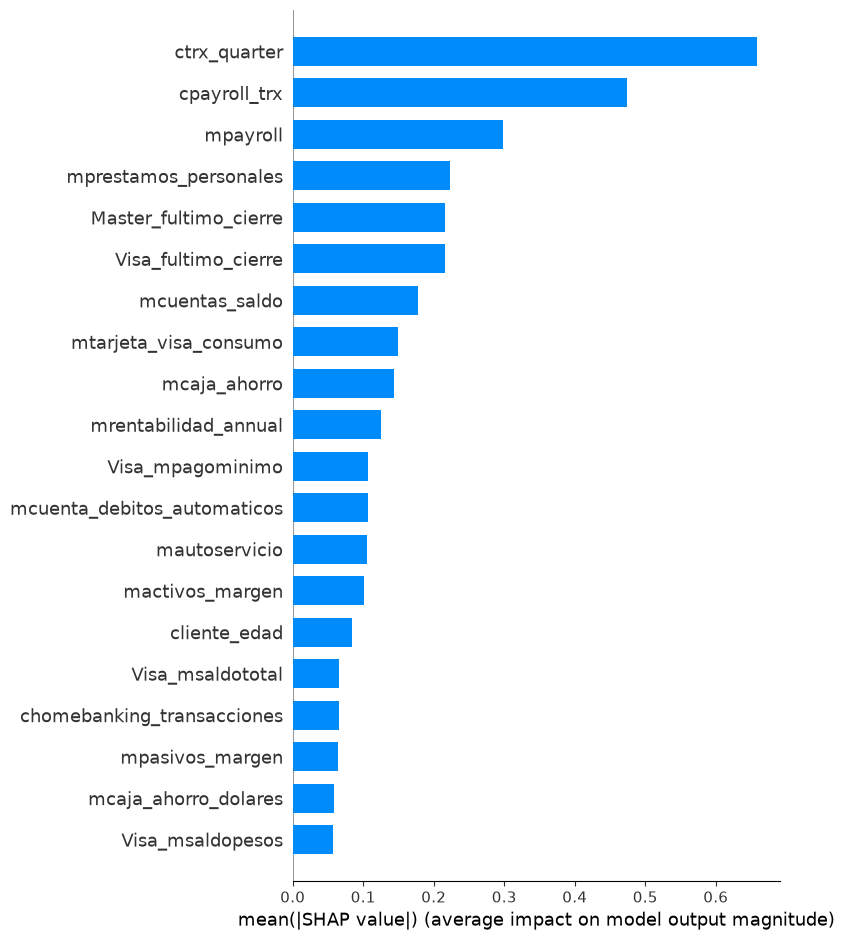

In [ ]:
shap.summary_plot(shap_values, X, 
                  feature_names=feats, plot_type="bar", 
                  color_bar=True, show=False)

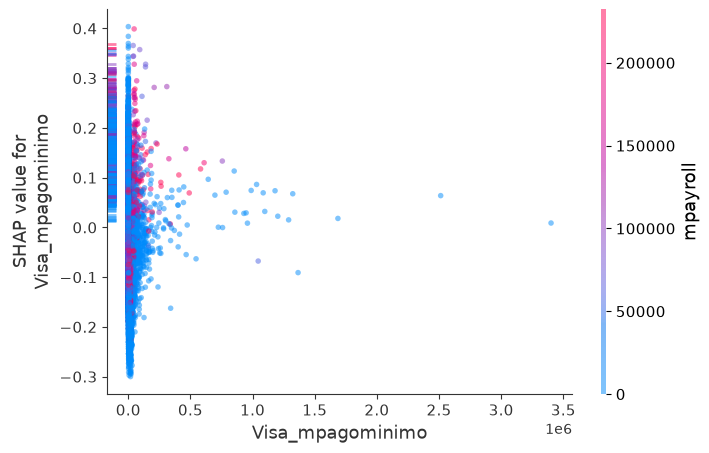

In [ ]:
shap.dependence_plot(
    "Visa_mpagominimo",  # índice de la característica a visualizar
    shap_values=shap_values.values, 
    features=X, 
    feature_names=feats, 
    display_features=df[feats],  # para mostrar los valores reales de la característica
    alpha=0.5,  # transparencia de los puntos
    show=False
)

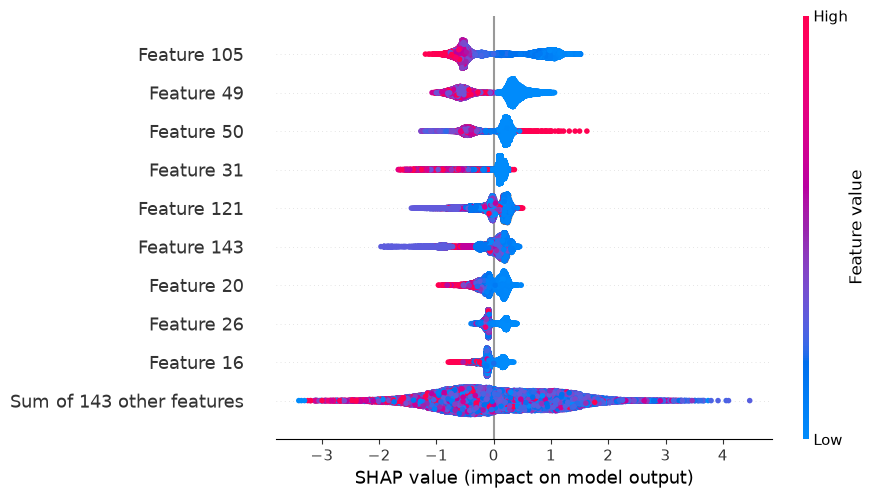

In [ ]:
%matplotlib inline
shap.plots.beeswarm(shap_values)

In [ ]:
# Perfiles interpretables por cluster
# Se combinan las caracteristicas observadas con las razones de prediccion del modelo.
import numpy as np
import pandas as pd

labels = np.asarray(clusters)
if len(labels) != len(df):
    raise ValueError(f"Hay {len(labels)} etiquetas para {len(df)} filas de df")

X_perfil = df.loc[:, feats].copy()
X_perfil["cluster"] = labels

# Valores SHAP en formato tabular, incluso si shap_values es un Explanation.
S = shap_values.values if hasattr(shap_values, "values") else np.asarray(shap_values)
if S.ndim == 3:
    S = S[:, :, 1]
if S.shape[0] != len(df):
    raise ValueError(f"Hay {S.shape[0]} filas SHAP para {len(df)} filas de df")

shap_perfil = pd.DataFrame(S, columns=feats, index=df.index)
shap_perfil["cluster"] = labels

# 1) Tamano y resultado observado de cada perfil.
resumen_clusters = X_perfil.groupby("cluster").agg(casos=(feats[0], "size"))
if GRUPO_COL in df.columns:
    resumen_clusters[f"tasa_{GRUPO_COL}"] = df.assign(cluster=labels).groupby("cluster")[GRUPO_COL].mean()
resumen_clusters["porcentaje"] = 100 * resumen_clusters["casos"] / len(df)
display(resumen_clusters.sort_index())

# 2) Variables originales que mas diferencian cada cluster del total.
media_global = X_perfil[feats].mean()
media_cluster = X_perfil.groupby("cluster")[feats].mean()
diferencia = media_cluster.subtract(media_global, axis="columns")

perfil_variables = []
for cluster in sorted(X_perfil["cluster"].unique()):
    top = diferencia.loc[cluster].abs().sort_values(ascending=False).head(10).index
    for variable in top:
        perfil_variables.append({
            "cluster": cluster,
            "variable": variable,
            "media_cluster": media_cluster.loc[cluster, variable],
            "diferencia_vs_total": diferencia.loc[cluster, variable],
        })
perfil_variables = pd.DataFrame(perfil_variables)
display(perfil_variables)

# 3) Variables que explican la prediccion dentro de cada cluster.
media_shap_cluster = shap_perfil.groupby("cluster")[feats].mean()
importancia_shap_cluster = shap_perfil.groupby("cluster")[feats].apply(lambda x: x.abs().mean())

for cluster in sorted(shap_perfil["cluster"].unique()):
    top = importancia_shap_cluster.loc[cluster].sort_values(ascending=False).head(10).index
    print(f"\nCluster {cluster}: razones principales del modelo")
    display(pd.DataFrame({
        "variable": top,
        "SHAP_medio": media_shap_cluster.loc[cluster, top].values,
        "SHAP_abs_medio": importancia_shap_cluster.loc[cluster, top].values,
    }))

# Matriz compacta para comparar los perfiles y asignarles nombres de negocio.
perfil_comparativo = X_perfil.groupby("cluster").size().to_frame("casos")
if GRUPO_COL in df.columns:
    perfil_comparativo[f"tasa_{GRUPO_COL}"] = df.assign(cluster=labels).groupby("cluster")[GRUPO_COL].mean()
perfil_comparativo

,casos,tasa_grupo,porcentaje
cluster,,,
-1,38120,0.360362,98.468215
0,362,0.983425,0.935086
1,57,1.000000,0.147237
2,77,0.948052,0.198900
3,45,0.800000,0.116240
4,52,1.000000,0.134322


,cluster,variable,media_cluster,diferencia_vs_total
0,-1,mcuentas_saldo,162526.146018,2670.370593
1,-1,Master_mfinanciacion_limite,682886.808078,2086.224653
2,-1,Visa_mfinanciacion_limite,445771.535610,1494.521624
3,-1,mtransferencias_recibidas,93875.000136,1429.138001
4,-1,mplazo_fijo_dolares,91006.664682,1394.026610
5,-1,mcaja_ahorro_dolares,83220.539453,1274.738312
6,-1,Visa_mlimitecompra,378763.922308,1070.737986
7,-1,mcaja_ahorro,64794.473885,991.390044
8,-1,mpayroll,57653.398340,883.126216
9,-1,Master_mlimitecompra,382106.809668,878.922138



Cluster -1: razones principales del modelo


,variable,SHAP_medio,SHAP_abs_medio
0,ctrx_quarter,0.000222,0.651749
1,cpayroll_trx,0.021834,0.476296
2,mpayroll,-0.014337,0.300181
3,mprestamos_personales,0.003337,0.223731
4,Visa_fultimo_cierre,-0.012566,0.217332
5,Master_fultimo_cierre,-0.022701,0.216963
6,mcuentas_saldo,-0.034119,0.176610
7,mtarjeta_visa_consumo,-0.008639,0.148602
8,mcaja_ahorro,-0.053168,0.143297
9,mrentabilidad_annual,0.000629,0.125327



Cluster 0: razones principales del modelo


,variable,SHAP_medio,SHAP_abs_medio
0,ctrx_quarter,1.089888,1.089888
1,cpayroll_trx,0.316664,0.316664
2,mcuentas_saldo,0.222973,0.222973
3,mtarjeta_visa_consumo,0.221579,0.221579
4,Master_fultimo_cierre,0.184821,0.184821
5,mprestamos_personales,0.178027,0.182935
6,mpayroll,0.171145,0.171145
7,Visa_mpagominimo,0.158824,0.158824
8,mcaja_ahorro,0.153842,0.155519
9,Visa_fultimo_cierre,0.125311,0.125311



Cluster 1: razones principales del modelo


,variable,SHAP_medio,SHAP_abs_medio
0,ctrx_quarter,0.981018,0.981018
1,cpayroll_trx,0.412751,0.412751
2,mpayroll,0.217241,0.217241
3,mtarjeta_visa_consumo,0.216938,0.216938
4,Master_fultimo_cierre,0.185994,0.185994
5,mcuentas_saldo,0.180502,0.180502
6,mprestamos_personales,0.175273,0.177343
7,Visa_mpagominimo,0.148262,0.148262
8,mcaja_ahorro,0.139990,0.139990
9,Visa_fultimo_cierre,0.139070,0.139070



Cluster 2: razones principales del modelo


,variable,SHAP_medio,SHAP_abs_medio
0,ctrx_quarter,1.044817,1.044817
1,cpayroll_trx,0.350838,0.350838
2,mtarjeta_visa_consumo,0.205915,0.205915
3,mprestamos_personales,0.194971,0.194971
4,mpayroll,0.194887,0.194887
5,Master_fultimo_cierre,0.122450,0.177425
6,mcuentas_saldo,0.170901,0.170901
7,mcaja_ahorro,0.170652,0.170652
8,Visa_fultimo_cierre,0.127705,0.136208
9,Visa_mpagominimo,0.119254,0.119254



Cluster 3: razones principales del modelo


,variable,SHAP_medio,SHAP_abs_medio
0,ctrx_quarter,1.043453,1.043453
1,cpayroll_trx,0.326581,0.326581
2,mprestamos_personales,0.210231,0.210231
3,mtarjeta_visa_consumo,0.195786,0.195786
4,cliente_edad,-0.191682,0.191682
5,mpayroll,0.189979,0.189979
6,mcaja_ahorro,0.182960,0.182960
7,mcuentas_saldo,0.174912,0.174912
8,Master_fultimo_cierre,0.109378,0.166191
9,Visa_fultimo_cierre,0.120381,0.125279



Cluster 4: razones principales del modelo


,variable,SHAP_medio,SHAP_abs_medio
0,ctrx_quarter,1.057053,1.057053
1,cpayroll_trx,0.349276,0.349276
2,mtarjeta_visa_consumo,0.213911,0.213911
3,mprestamos_personales,0.206747,0.206747
4,mpayroll,0.206703,0.206703
5,mcuentas_saldo,0.182506,0.182506
6,Master_fultimo_cierre,0.176510,0.176510
7,mcaja_ahorro,0.162465,0.162465
8,mrentabilidad_annual,0.149782,0.149782
9,Visa_fultimo_cierre,0.148370,0.148370


,casos,tasa_grupo
cluster,,
-1,38120,0.360362
0,362,0.983425
1,57,1.000000
2,77,0.948052
3,45,0.800000
4,52,1.000000


In [ ]:
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import DBSCAN


# 4. Agrupar con DBSCAN
dbscan = DBSCAN(
    eps=2,
    min_samples=20,
    metric="euclidean"
)

s_labels = dbscan.fit_predict(s_2d)

# resultado = df.copy()
# resultado["cluster"] = clusters
# resultado["prediccion"] = modelo.predict_proba(X_test)[:, 1]

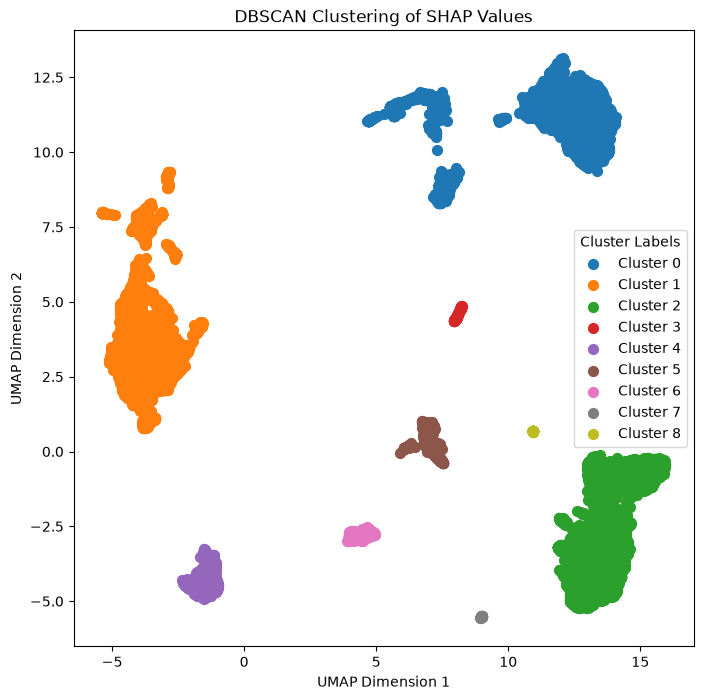

In [ ]:
%matplotlib inline
fig, ax = plt.subplots(figsize=(8, 8))
for cluster in sorted(set(s_labels)):
    mask = s_labels == cluster
    nombre = "Ruido" if cluster == -1 else f"Cluster {cluster}"

    ax.scatter(
        s_2d[mask, 0],
        s_2d[mask, 1],
        label=nombre,
        s=50
    )
ax.set_title('DBSCAN Clustering of SHAP Values')
ax.set_xlabel('UMAP Dimension 1')
ax.set_ylabel('UMAP Dimension 2')   
ax.legend(title='Cluster Labels')

plt.show()

In [ ]:
df_s_2d = pd.DataFrame(s_2d, columns=["UMAP1", "UMAP2"])
df_s_2d["Cluster"] = s_labels

df[["UMAP1", "UMAP2", "Cluster"]] = df_s_2d[["UMAP1", "UMAP2", "Cluster"]]


,numero_de_cliente,foto_mes,active_quarter,cliente_vip,internet,cliente_edad,cliente_antiguedad,mrentabilidad,mrentabilidad_annual,mcomisiones,...,Visa_fechaalta,Visa_mconsumototal,Visa_cconsumos,Visa_cadelantosefectivo,Visa_mpagominimo,clase_ternaria,grupo,UMAP1,UMAP2,Cluster
34,12188338,202104,1,0,0,64,317,-391.28,40927.24,89.07,...,8381,221.68,2,0,0.00,BAJA+1,1,19.546715,6.535058,3
399,12564666,202104,1,0,2,59,47,7632.21,123736.25,3392.33,...,1425,2197.00,2,0,8199.27,CONTINUA,1,19.554245,6.526911,3
474,12615410,202104,1,0,0,66,282,352.07,10082.19,261.07,...,8536,3406.97,1,0,234.60,BAJA+1,1,19.551752,6.529886,3
569,12714361,202107,1,0,0,61,208,-625.71,7044.72,24.45,...,4605,0.00,0,0,0.00,BAJA+1,1,19.536570,6.544575,3
611,12788105,202105,1,0,0,65,324,4034.26,-23769.50,3546.98,...,9336,28995.32,18,0,5900.19,CONTINUA,1,19.544310,6.537508,3
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
38416,74768609,202106,1,0,0,38,12,2624.47,5115.48,1599.37,...,350,614.65,1,0,37195.83,BAJA+1,1,19.556139,6.526085,3
38427,74875416,202104,1,0,0,35,11,1857.94,7267.88,1592.20,...,306,0.00,0,0,0.00,BAJA+1,1,19.548786,6.533422,3
38452,75043980,202104,1,0,0,25,11,2718.56,5357.03,1592.20,...,389,0.00,0,0,35835.15,BAJA+1,1,19.563450,6.518950,3
38579,75675629,202107,1,0,0,32,11,3875.86,-29678.51,620.55,...,307,0.00,0,0,758367.96,BAJA+1,1,19.559492,6.522345,3


In [ ]:
df.loc[df["grupo"] == 1,] 

,numero_de_cliente,foto_mes,active_quarter,cliente_vip,internet,cliente_edad,cliente_antiguedad,mrentabilidad,mrentabilidad_annual,mcomisiones,...,Visa_fechaalta,Visa_mconsumototal,Visa_cconsumos,Visa_cadelantosefectivo,Visa_mpagominimo,clase_ternaria,grupo,UMAP1,UMAP2,Cluster
24,12176834,202103,1,0,2,63,322,3774.06,44482.37,3147.42,...,<NA>,NaN,<NA>,<NA>,NaN,CONTINUA,1,12.558481,-4.256675,2
25,12176834,202104,1,0,1,63,323,4027.07,43832.13,3147.42,...,<NA>,NaN,<NA>,<NA>,NaN,BAJA+2,1,12.543432,-4.252933,2
26,12176834,202105,1,0,0,63,324,3892.67,42438.85,3147.42,...,<NA>,NaN,<NA>,<NA>,NaN,BAJA+1,1,12.564551,-4.261809,2
33,12188338,202103,1,0,2,64,316,4120.65,40495.90,344.01,...,8351,10781.85,8,0,52831.92,BAJA+2,1,12.064334,11.461161,0
34,12188338,202104,1,0,0,64,317,-391.28,40927.24,89.07,...,8381,221.68,2,0,0.00,BAJA+1,1,19.546715,6.535058,3
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
38708,77733822,202105,0,0,0,25,1,0.00,0.00,0.00,...,11,NaN,<NA>,<NA>,0.00,CONTINUA,1,14.506637,-3.367153,2
38709,77733822,202106,0,0,0,25,2,0.00,0.00,0.00,...,41,NaN,<NA>,<NA>,0.00,BAJA+2,1,13.604184,-4.988615,2
38710,77733822,202107,0,0,0,25,3,0.00,0.00,0.00,...,72,NaN,<NA>,<NA>,0.00,BAJA+1,1,14.380696,-2.492217,2
38711,77820127,202105,1,0,0,33,1,30.55,30.55,0.00,...,15,NaN,<NA>,<NA>,0.00,BAJA+2,1,3.917001,-1.655298,6


In [ ]:

log(f"entrenando RF ({N_TREES} arboles, min_samples_leaf={MIN_SAMPLES_LEAF})")
rf = entrenar_rf(X, y, N_TREES, MIN_SAMPLES_LEAF, SEED)
log(f"OOB accuracy {rf.oob_score_:.4f}")

In [ ]:
ids_churn = df.loc[df[GRUPO_COL] == 1, ID_COL].index
P_churn = df.loc[ids_churn]

# labels = clusterizar(P_churn, K, SEED)
tam = labels.value_counts().sort_index()
log("clusters: " + ", ".join(f"cluster_{c}={n:,}" for c, n in tam.items()))

attrs_def = caracterizar_clusters(P_churn, labels, TOP_N, share_min=0.5 / P_churn.shape[1])
for c, g in attrs_def.groupby(CLUSTER_COL):
    log(f"  cluster_{c}: " + ", ".join(f"{r.atributo} (lift {r.lift:.1f})" for r in g.itertuples()))
lift_all = P_churn.groupby(labels).mean() / P_churn.mean(axis=0)

NameError: name 'labels' is not defined